# 🇳🇬 Igbo VQA System — GPU Training & Dual Encoder Comparison
### Development of a Vision Question Answering System for Object Detection and Recognition in Igbo Language
**Igboji, Ebuka Andrew (2024516019FN)**  
Nnamdi Azikiwe University, Awka — M.Sc. Computer Science

---
### 🎯 Core Architecture & Pipeline Fixes Applied:
1. **Dual Tokenizer & Vocabulary Alignment**: Questions use XLM-R / mBERT tokenizer; answer targets use mT5 tokenizer with -100 padding mask.
2. **Spatial Multi-Patch Cross-Attention**: Uses all 50 CLIP visual patch tokens (rather than a single pooled vector), enabling genuine spatial attention.
3. **Higher Learning Rate**: 3e-4 AdamW for mT5 decoder & fusion (and 3e-5 for pretrained text backbone), moving scores off zero.
4. **Strict fp32 Precision**: Avoids fp16 underflow/overflow in mT5 (which causes NaNs and blank predictions).
5. **Diverse Questions & Concise Targets**: Varied question types (object, action, color, yes/no) with short-answer mode.
6. **Morphology-Aware Metrics**: Reports **chrF** (Popović 2015), Unicode-safe **ROUGE-L** (preserving ị, ọ, ụ, ṅ), **BLEU 1-4**, **Exact Match**, and **Soft Accuracy**.
7. **Fast 50-Sample Overfit Verification**: Built-in sanity test before full training.

---
**Runtime:** Runtime → Change runtime type → **T4 GPU**
**Expected training time per model:** ~25–45 min on T4 GPU

---
**ONE-PASS VERSION.** Run all cells top to bottom (Runtime > Run all) and everything is rebuilt, including after a Colab reset.
- The patched decoding (repetition penalty 1.25, no repeated 3-grams) is now written **into the model file** (Step 2), so training, the overfit test and evaluation all use it.
- Step 6 backs up checkpoints to Drive *before* the extra evaluation runs.
- Step 7 is the full final evaluation (full test set, confidence intervals, image controls, breakdown by question type). It replaces the earlier "Thesis Correction 1-3" cells.
- The from-scratch decoder ablation at the end is **off by default** (`RUN_SCRATCH_ABLATION = False`).

## 🔧 Step 1: Setup — Mount Drive & Install Dependencies

In [1]:
# Mount Google Drive to persist checkpoints and results
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_DIR = '/content/drive/MyDrive/IgboVQA'
os.makedirs(DRIVE_DIR, exist_ok=True)
print(f"✓ Drive mounted. Results will be saved to: {DRIVE_DIR}")

Mounted at /content/drive
✓ Drive mounted. Results will be saved to: /content/drive/MyDrive/IgboVQA


In [2]:
# Install all required dependencies
!pip install -q "transformers>=4.35.0" "datasets>=2.14.0" "huggingface_hub>=0.17.0"
!pip install -q sentencepiece sacrebleu rouge_score
!pip install -q torch torchvision Pillow requests tqdm matplotlib seaborn
print("✓ All dependencies installed")

# Check GPU device
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✓ Device: {device}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("⚠ No GPU found! Please go to Runtime → Change runtime type → T4 GPU")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✓ All dependencies installed
✓ Device: cuda
  GPU: Tesla T4
  VRAM: 15.6 GB


## 📁 Step 2: Write Architecture & Training Modules

In [3]:
import os
PROJECT = "/content/igbo_vqa"
for d in ["data/images", "data/cache", "checkpoints/xlmr", "checkpoints/mbert",
          "results/xlmr", "results/mbert", "models", "training", "evaluation", "logs"]:
    os.makedirs(f"{PROJECT}/{d}", exist_ok=True)
print(f"✓ Project directories initialized at {PROJECT}")

✓ Project directories initialized at /content/igbo_vqa


In [4]:
%%writefile /content/igbo_vqa/config.py
"""config.py — Central configuration for the Igbo VQA System (GPU/Colab)"""
import os

BASE_DIR       = "/content/igbo_vqa"
DATA_DIR       = f"{BASE_DIR}/data"
IMAGES_DIR     = f"{DATA_DIR}/images"
CACHE_DIR      = f"{DATA_DIR}/cache"
CHECKPOINT_DIR = f"{BASE_DIR}/checkpoints"
RESULTS_DIR    = f"{BASE_DIR}/results"
LOG_DIR        = f"{BASE_DIR}/logs"

XLMR_CHECKPOINT_DIR  = f"{CHECKPOINT_DIR}/xlmr"
MBERT_CHECKPOINT_DIR = f"{CHECKPOINT_DIR}/mbert"
XLMR_RESULTS_DIR     = f"{RESULTS_DIR}/xlmr"
MBERT_RESULTS_DIR    = f"{RESULTS_DIR}/mbert"

for d in [DATA_DIR, IMAGES_DIR, CACHE_DIR, CHECKPOINT_DIR, XLMR_CHECKPOINT_DIR,
          MBERT_CHECKPOINT_DIR, RESULTS_DIR, XLMR_RESULTS_DIR, MBERT_RESULTS_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

DATASET_NAME   = "AfriMM/AFRICaption"
IGBO_COLUMN    = "ibo"
ENG_COLUMN     = "eng"
IMAGE_ID_COL   = "image_id"
MAX_SAMPLES    = 6000
TRAIN_SPLIT    = 0.70
VAL_SPLIT      = 0.15
TEST_SPLIT     = 0.15
ANSWER_MODE    = "short"

FLICKR8K_ZIP_URL = "https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_Dataset.zip"

VISUAL_ENCODER_NAME = "openai/clip-vit-base-patch32"
VISUAL_EMBED_DIM    = 768
VISUAL_NUM_PATCHES  = 50
IMAGE_SIZE          = 224
UNFREEZE_CLIP_LAYERS = 0

ENCODER_VARIANTS = {
    "xlmr":  "xlm-roberta-base",
    "mbert": "bert-base-multilingual-cased",
}
TEXT_ENCODER_NAME = "xlm-roberta-base"
TEXT_EMBED_DIM    = 768
MAX_TEXT_LENGTH   = 64

FUSION_DIM    = 512
FUSION_HEADS  = 8
FUSION_LAYERS = 2
DROPOUT       = 0.1

DECODER_NAME      = "google/mt5-small"
MAX_ANSWER_LENGTH = 32
MIN_ANSWER_LENGTH = 1

BATCH_SIZE             = 16
LEARNING_RATE          = 3e-4
BACKBONE_LEARNING_RATE = 3e-5
WEIGHT_DECAY           = 0.01
NUM_EPOCHS             = 10
WARMUP_STEPS           = 150
GRADIENT_CLIP          = 1.0
SEED                   = 42
USE_FP16               = False
FREEZE_VISUAL_ENCODER  = True
FREEZE_TEXT_ENCODER    = False

IGBO_QUESTION_TEMPLATES = [
    {"template": "Gwa m ihe ị hụ n'onyinyo a.", "type": "general", "en": "Tell me what you see in this image."},
    {"template": "Kedu ihe dị n'onyinyo a?", "type": "general", "en": "What is in this image?"},
    {"template": "Kọwaa ihe na-eme n'onyinyo a.", "type": "general", "en": "Describe what is happening in this image."},
    {"template": "Kedu ihe a na-ahụ na foto a?", "type": "object", "en": "What is seen in this picture?"},
    {"template": "Onye ma ọ bụ gịnị dị na foto a?", "type": "object", "en": "Who or what is in this picture?"},
    {"template": "Kedu ihe ndị mmadụ na-eme n'onyinyo a?", "type": "action", "en": "What are the people doing in this image?"},
    {"template": "Gịnị ka a na-eme n'ebe a?", "type": "action", "en": "What is being done here?"},
    {"template": "Kedu agba pụtara ìhè n'onyinyo a?", "type": "color", "en": "What color is prominent in this image?"},
    {"template": "Ọ dị ihe na-eme n'onyinyo a?", "type": "yes_no", "en": "Is something happening in this image?"},
]

NUM_BEAMS        = 4
TEMPERATURE      = 1.0
BEST_CHECKPOINT       = f"{CHECKPOINT_DIR}/best_model.pt"
XLMR_BEST_CHECKPOINT  = f"{XLMR_CHECKPOINT_DIR}/best_model.pt"
MBERT_BEST_CHECKPOINT = f"{MBERT_CHECKPOINT_DIR}/best_model.pt"

def get_checkpoint_path(encoder="xlmr"):
    return XLMR_BEST_CHECKPOINT if encoder == "xlmr" else MBERT_BEST_CHECKPOINT

def get_results_dir(encoder="xlmr"):
    return XLMR_RESULTS_DIR if encoder == "xlmr" else MBERT_RESULTS_DIR

LOG_EVERY_N_STEPS   = 20
SAVE_EVERY_N_EPOCHS = 2
EVAL_EVERY_N_EPOCHS = 1
print("✓ config.py written")

Writing /content/igbo_vqa/config.py


In [5]:
%%writefile /content/igbo_vqa/data/dataset.py
"""data/dataset.py — AFRICaption Igbo VQA Pipeline with Flickr8k Zip & Dual Tokenizers"""
import os, sys, json, random, logging, zipfile, requests
from typing import Dict, List, Optional, Tuple
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm import tqdm
sys.path.insert(0, "/content/igbo_vqa")
import config
logger = logging.getLogger(__name__)

_PLACEHOLDER_WARNED = False

def ensure_flickr8k_images(cache_dir=config.IMAGES_DIR, min_expected=100):
    os.makedirs(cache_dir, exist_ok=True)
    existing = [f for f in os.listdir(cache_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if len(existing) >= min_expected:
        return len(existing)

    zip_path = os.path.join(config.DATA_DIR, "Flickr8k_Dataset.zip")
    print(f"Downloading Flickr8k images from {config.FLICKR8K_ZIP_URL} ...")
    with requests.get(config.FLICKR8K_ZIP_URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        total_bytes = int(r.headers.get("content-length", 0))
        with open(zip_path, "wb") as f, tqdm(total=total_bytes, unit="B", unit_scale=True, desc="Flickr8k_Dataset.zip") as pbar:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))

    print(f"Extracting images into {cache_dir} ...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [m for m in zf.namelist() if os.path.basename(m).lower().endswith((".jpg", ".jpeg", ".png"))]
        for member in tqdm(members, desc="Extracting Flickr8k"):
            target = os.path.join(cache_dir, os.path.basename(member))
            if not os.path.exists(target):
                with zf.open(member) as src, open(target, "wb") as dst:
                    dst.write(src.read())

    if os.path.exists(zip_path):
        os.remove(zip_path)
    existing = [f for f in os.listdir(cache_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    print(f"✓ Extracted {len(existing)} Flickr8k images")
    return len(existing)

def download_image(image_id, cache_dir):
    global _PLACEHOLDER_WARNED
    cache_path = os.path.join(cache_dir, os.path.basename(image_id))
    if os.path.exists(cache_path):
        try:
            return Image.open(cache_path).convert("RGB")
        except Exception:
            pass
    if not _PLACEHOLDER_WARNED:
        print(f"⚠ Missing local image '{image_id}' in {cache_dir}; falling back to placeholder.")
        _PLACEHOLDER_WARNED = True
    return None

def create_placeholder_image():
    return Image.new("RGB", (config.IMAGE_SIZE, config.IMAGE_SIZE), color=(128, 128, 128))

def _extract_short_answer(caption, q_type):
    toks = caption.strip().split()
    if not toks: return caption.strip()
    if q_type == "yes_no": return "Ee"
    if q_type == "object":
        cutoff = min(3, len(toks))
        for i, t in enumerate(toks[:4]):
            if t.startswith("na-") or t == "na":
                cutoff = max(1, i); break
        return " ".join(toks[:cutoff])
    if q_type == "action":
        for i, t in enumerate(toks):
            if t.startswith("na-") or t == "na":
                return " ".join(toks[i:min(i+4, len(toks))])
        return " ".join(toks[:min(4, len(toks))])
    if config.ANSWER_MODE == "short" and len(toks) > 6:
        return " ".join(toks[:6])
    return caption.strip()

def create_vqa_pairs(records):
    pairs = []
    for rec in records:
        ibo = rec.get(config.IGBO_COLUMN, "")
        img_id = rec.get(config.IMAGE_ID_COL, "")
        if not ibo or not img_id or len(ibo.strip()) < 5: continue
        t_item = random.choice(config.IGBO_QUESTION_TEMPLATES)
        ans = _extract_short_answer(ibo, t_item["type"]) if config.ANSWER_MODE == "short" else ibo.strip()
        pairs.append({
            "image_id": img_id, "question_igbo": t_item["template"],
            "question_eng": t_item["en"], "question_type": t_item["type"],
            "answer_igbo": ans, "full_caption": ibo.strip(),
            "answer_eng": rec.get(config.ENG_COLUMN, "").strip()
        })
    return pairs

class IgboVQADataset(Dataset):
    def __init__(self, vqa_pairs, image_processor, text_tokenizer, decoder_tokenizer=None,
                 cache_dir=config.IMAGES_DIR, max_text_length=config.MAX_TEXT_LENGTH, split="train"):
        self.vqa_pairs = vqa_pairs
        self.image_processor = image_processor
        self.text_tokenizer = text_tokenizer
        if decoder_tokenizer is None:
            from transformers import AutoTokenizer
            self.decoder_tokenizer = AutoTokenizer.from_pretrained(config.DECODER_NAME, use_fast=False)
        else:
            self.decoder_tokenizer = decoder_tokenizer
        self.cache_dir = cache_dir
        self.max_text_length = max_text_length
        self.split = split

    def __len__(self): return len(self.vqa_pairs)

    def __getitem__(self, idx):
        pair = self.vqa_pairs[idx]
        img = download_image(pair["image_id"], self.cache_dir) or create_placeholder_image()
        pv = self.image_processor(images=img, return_tensors="pt")["pixel_values"].squeeze(0)
        q_enc = self.text_tokenizer(pair["question_igbo"], max_length=self.max_text_length,
                                   padding="max_length", truncation=True, return_tensors="pt")
        a_enc = self.decoder_tokenizer(pair["answer_igbo"], max_length=config.MAX_ANSWER_LENGTH,
                                       padding="max_length", truncation=True, return_tensors="pt")
        labels = a_enc["input_ids"].squeeze(0).clone()
        labels[labels == self.decoder_tokenizer.pad_token_id] = -100
        return {
            "pixel_values": pv,
            "question_ids": q_enc["input_ids"].squeeze(0),
            "question_mask": q_enc["attention_mask"].squeeze(0),
            "labels": labels,
            "answer_text": pair["answer_igbo"],
            "question_text": pair["question_igbo"],
            "image_id": pair["image_id"]
        }

def load_africaption_dataset(max_samples=config.MAX_SAMPLES):
    cache_path = os.path.join(config.CACHE_DIR, f"africaption_{max_samples}.json")
    if os.path.exists(cache_path):
        with open(cache_path, "r", encoding="utf-8") as f: return json.load(f)
    from datasets import load_dataset
    ds = load_dataset(config.DATASET_NAME, split="train", cache_dir=config.CACHE_DIR)
    ds = ds.filter(lambda x: x[config.IGBO_COLUMN] and len(str(x[config.IGBO_COLUMN]).strip()) > 5)
    if max_samples and len(ds) > max_samples:
        random.seed(config.SEED); idx = list(range(len(ds))); random.shuffle(idx)
        ds = ds.select(idx[:max_samples])
    records = [{"image_id": str(r[config.IMAGE_ID_COL]), "ibo": str(r[config.IGBO_COLUMN]), "eng": str(r.get(config.ENG_COLUMN,""))} for r in ds]
    with open(cache_path, "w", encoding="utf-8") as f: json.dump(records, f, ensure_ascii=False)
    return records

def split_dataset(records, seed=config.SEED):
    random.seed(seed); s = records.copy(); random.shuffle(s)
    n = len(s); nt = int(n * config.TRAIN_SPLIT); nv = int(n * config.VAL_SPLIT)
    return s[:nt], s[nt:nt+nv], s[nt+nv:]

def get_dataloaders(image_processor, tokenizer, batch_size=config.BATCH_SIZE, max_samples=config.MAX_SAMPLES, decoder_tokenizer=None):
    ensure_flickr8k_images(config.IMAGES_DIR)
    records = load_africaption_dataset(max_samples)
    matched = sum(1 for r in records if os.path.exists(os.path.join(config.IMAGES_DIR, os.path.basename(r["image_id"]))))
    print(f"✓ Matched real Flickr8k images: {matched}/{len(records)}")
    if matched == 0:
        raise RuntimeError("0 Flickr8k images matched on disk! Cannot train on blank placeholders.")
    random.seed(config.SEED)
    pairs = create_vqa_pairs(records)
    tr, va, te = split_dataset(pairs)
    kw = dict(image_processor=image_processor, text_tokenizer=tokenizer, decoder_tokenizer=decoder_tokenizer)
    return (
        DataLoader(IgboVQADataset(tr, split="train", **kw), batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True),
        DataLoader(IgboVQADataset(va, split="val",   **kw), batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True),
        DataLoader(IgboVQADataset(te, split="test",  **kw), batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    )
print("✓ dataset.py written")

Writing /content/igbo_vqa/data/dataset.py


In [6]:
%%writefile /content/igbo_vqa/models/igbo_vqa_model.py
"""models/igbo_vqa_model.py — 5-Module Pipeline with Patch Cross-Attention, Dual Tokenizers and patched decoding (repetition_penalty=1.25, no_repeat_ngram_size=3)"""
import sys, logging
sys.path.insert(0, "/content/igbo_vqa")
import config
import torch
import torch.nn as nn
from transformers.modeling_outputs import BaseModelOutput
logger = logging.getLogger(__name__)

class VisualEncoder(nn.Module):
    def __init__(self, model_name=config.VISUAL_ENCODER_NAME, freeze=config.FREEZE_VISUAL_ENCODER):
        super().__init__()
        from transformers import CLIPVisionModel
        self.clip = CLIPVisionModel.from_pretrained(model_name)
        if freeze:
            for p in self.clip.parameters(): p.requires_grad = False
        self.projection = nn.Sequential(
            nn.Linear(config.VISUAL_EMBED_DIM, config.FUSION_DIM),
            nn.LayerNorm(config.FUSION_DIM), nn.GELU())
    def forward(self, pixel_values):
        out = self.clip(pixel_values=pixel_values)
        return self.projection(out.last_hidden_state)  # (B, 50, FUSION_DIM)

class TextEncoder(nn.Module):
    def __init__(self, model_name=config.TEXT_ENCODER_NAME, freeze=config.FREEZE_TEXT_ENCODER):
        super().__init__()
        from transformers import AutoModel
        self.backbone = AutoModel.from_pretrained(model_name)
        if freeze:
            for p in self.backbone.parameters(): p.requires_grad = False
        self.projection = nn.Sequential(
            nn.Linear(config.TEXT_EMBED_DIM, config.FUSION_DIM),
            nn.LayerNorm(config.FUSION_DIM), nn.GELU())
    def forward(self, input_ids, attention_mask):
        out = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        return self.projection(out.last_hidden_state)  # (B, seq_len, FUSION_DIM)

class CrossModalFusion(nn.Module):
    def __init__(self, fusion_dim=config.FUSION_DIM, num_heads=config.FUSION_HEADS, num_layers=config.FUSION_LAYERS, dropout=config.DROPOUT):
        super().__init__()
        self.attn_layers = nn.ModuleList([nn.MultiheadAttention(fusion_dim, num_heads, dropout=dropout, batch_first=True) for _ in range(num_layers)])
        self.ffn_layers  = nn.ModuleList([nn.Sequential(nn.Linear(fusion_dim, fusion_dim*4), nn.GELU(), nn.Dropout(dropout), nn.Linear(fusion_dim*4, fusion_dim)) for _ in range(num_layers)])
        self.ln1 = nn.ModuleList([nn.LayerNorm(fusion_dim) for _ in range(num_layers)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(fusion_dim) for _ in range(num_layers)])
        self.dropout = nn.Dropout(dropout)
    def forward(self, visual_tokens, text_tokens, text_mask):
        fused_text = text_tokens
        for i, attn in enumerate(self.attn_layers):
            out, _ = attn(query=fused_text, key=visual_tokens, value=visual_tokens)
            fused_text = self.ln1[i](fused_text + self.dropout(out))
            fused_text = self.ln2[i](fused_text + self.dropout(self.ffn_layers[i](fused_text)))
        multimodal_seq = torch.cat([visual_tokens, fused_text], dim=1)
        v_mask = torch.ones((visual_tokens.size(0), visual_tokens.size(1)), dtype=text_mask.dtype, device=text_mask.device)
        multimodal_mask = torch.cat([v_mask, text_mask], dim=1)
        return multimodal_seq, multimodal_mask

class IgboVQAModel(nn.Module):
    def __init__(self, text_encoder_name=config.TEXT_ENCODER_NAME, decoder_name=config.DECODER_NAME):
        super().__init__()
        from transformers import MT5ForConditionalGeneration, AutoTokenizer
        self.text_encoder_name = text_encoder_name
        self.visual_encoder    = VisualEncoder()
        self.text_encoder      = TextEncoder(model_name=text_encoder_name)
        self.fusion            = CrossModalFusion()
        self.decoder           = MT5ForConditionalGeneration.from_pretrained(decoder_name)
        self.mt5_tokenizer     = AutoTokenizer.from_pretrained(decoder_name, use_fast=False)
        d_model = self.decoder.config.d_model
        self.fusion_to_decoder = nn.Sequential(
            nn.Linear(config.FUSION_DIM, d_model),
            nn.LayerNorm(d_model),
        )
    def forward(self, pixel_values, question_ids, question_mask, labels=None):
        vt = self.visual_encoder(pixel_values)
        tt = self.text_encoder(question_ids, question_mask)
        mm_seq, mm_mask = self.fusion(vt, tt, question_mask)
        mm_h = self.fusion_to_decoder(mm_seq)
        enc_out = BaseModelOutput(last_hidden_state=mm_h)
        out = self.decoder(encoder_outputs=enc_out, attention_mask=mm_mask, labels=labels)
        return {"loss": out.loss, "logits": out.logits}
    @torch.no_grad()
    def generate_answer(self, pixel_values, question_ids, question_mask, num_beams=config.NUM_BEAMS, max_length=config.MAX_ANSWER_LENGTH):
        self.eval()
        vt = self.visual_encoder(pixel_values)
        tt = self.text_encoder(question_ids, question_mask)
        mm_seq, mm_mask = self.fusion(vt, tt, question_mask)
        mm_h = self.fusion_to_decoder(mm_seq)
        enc_out = BaseModelOutput(last_hidden_state=mm_h)
        sid = self.decoder.config.decoder_start_token_id
        if sid is None:
            sid = self.decoder.config.pad_token_id
        gen_ids = self.decoder.generate(encoder_outputs=enc_out, attention_mask=mm_mask, num_beams=num_beams, max_new_tokens=max_length, decoder_start_token_id=sid, repetition_penalty=1.25, no_repeat_ngram_size=3, early_stopping=True)
        return self.mt5_tokenizer.batch_decode(gen_ids, skip_special_tokens=True)
print("✓ igbo_vqa_model.py written")

Writing /content/igbo_vqa/models/igbo_vqa_model.py


In [7]:
%%writefile /content/igbo_vqa/evaluation/metrics.py
"""evaluation/metrics.py — chrF, SacreBLEU, Unicode ROUGE-L, EM, Soft Accuracy"""
import re
import sacrebleu
from rouge_score import rouge_scorer

def normalise_igbo(text):
    if not text: return ""
    t = text.lower().strip()
    t = re.sub(r"[^\w\s\u0300-\u036f\u1e00-\u1eff]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

class UnicodeIgboTokenizer:
    def tokenize(self, text):
        return [tok for tok in normalise_igbo(text).split() if tok]

def compute_chrf(preds, refs, beta=2.0):
    p = [normalise_igbo(x) for x in preds]; r = [normalise_igbo(x) for x in refs]
    return round(float(sacrebleu.corpus_chrf(p, [r], beta=beta).score), 4)

def compute_bleu(preds, refs):
    p = [normalise_igbo(x) for x in preds]; r = [normalise_igbo(x) for x in refs]
    res = {}
    for n in range(1, 5):
        b = sacrebleu.BLEU(max_ngram_order=n, smooth_method="exp").corpus_score(p, [r])
        res[f"bleu{n}"] = round(float(b.score), 4)
    return res

def compute_rouge(preds, refs):
    scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=False, tokenizer=UnicodeIgboTokenizer())
    scores = [scorer.score(normalise_igbo(r), normalise_igbo(p))["rougeL"].fmeasure for p, r in zip(preds, refs)]
    return round(sum(scores) / max(len(scores), 1), 4)

def compute_exact_match(preds, refs):
    return round(sum(normalise_igbo(p) == normalise_igbo(r) for p, r in zip(preds, refs)) / max(len(preds), 1), 4)

def compute_soft_accuracy(preds, refs):
    scores = []
    for p, r in zip(preds, refs):
        pt, rt = set(normalise_igbo(p).split()), set(normalise_igbo(r).split())
        scores.append(len(pt & rt) / max(len(rt), 1) if rt else 0.0)
    return round(sum(scores) / max(len(scores), 1), 4)

def compute_all_metrics(preds, refs):
    m = {"chrf": compute_chrf(preds, refs)}
    m.update(compute_bleu(preds, refs))
    m["rouge_l"]       = compute_rouge(preds, refs)
    m["exact_match"]   = compute_exact_match(preds, refs)
    m["soft_accuracy"] = compute_soft_accuracy(preds, refs)
    return m
print("✓ metrics.py written")

Writing /content/igbo_vqa/evaluation/metrics.py


In [8]:
%%writefile /content/igbo_vqa/training/train_model.py
"""training/train_model.py — GPU Training & Overfit Test Module"""
import os, sys, time, logging, json, random
sys.path.insert(0, "/content/igbo_vqa")
import config
import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import LinearLR, ConstantLR, SequentialLR
from tqdm import tqdm
from evaluation.metrics import compute_all_metrics
logger = logging.getLogger(__name__)

def build_optimizer(model, n_steps):
    no_decay = ["bias", "LayerNorm.weight", "layer_norm.weight", "LayerNorm.bias"]
    bb_decay, bb_no_decay, df_decay, df_no_decay = [], [], [], []
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        is_nd = any(nd in n for nd in no_decay)
        if "text_encoder.backbone" in n or "visual_encoder.clip" in n:
            (bb_no_decay if is_nd else bb_decay).append(p)
        else:
            (df_no_decay if is_nd else df_decay).append(p)
    groups = [
        {"params": df_decay,    "lr": config.LEARNING_RATE,          "weight_decay": config.WEIGHT_DECAY},
        {"params": df_no_decay, "lr": config.LEARNING_RATE,          "weight_decay": 0.0},
        {"params": bb_decay,    "lr": config.BACKBONE_LEARNING_RATE, "weight_decay": config.WEIGHT_DECAY},
        {"params": bb_no_decay, "lr": config.BACKBONE_LEARNING_RATE, "weight_decay": 0.0},
    ]
    groups = [g for g in groups if g["params"]]
    opt = AdamW(groups)
    warmup_steps = min(config.WARMUP_STEPS, max(1, int(n_steps * 0.1)))
    warmup = LinearLR(opt, start_factor=0.1, end_factor=1.0, total_iters=warmup_steps)
    const  = ConstantLR(opt, factor=1.0, total_iters=max(1, n_steps - warmup_steps))
    sched  = SequentialLR(opt, [warmup, const], milestones=[warmup_steps])
    return opt, sched

def run_overfit_test(encoder_key="xlmr", n_samples=50, epochs=30):
    from transformers import CLIPProcessor, AutoTokenizer
    from data.dataset import get_dataloaders
    from models.igbo_vqa_model import IgboVQAModel
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    name = config.ENCODER_VARIANTS[encoder_key]
    print(f"=== OVERFIT TEST ({n_samples} samples, {epochs} epochs) | {encoder_key.upper()} ===")
    ip = CLIPProcessor.from_pretrained(config.VISUAL_ENCODER_NAME)
    tk = AutoTokenizer.from_pretrained(name)
    model = IgboVQAModel(text_encoder_name=name).to(device)
    tr, _, _ = get_dataloaders(ip, tk, batch_size=8, decoder_tokenizer=model.mt5_tokenizer)
    sample_list = []
    for b in tr:
        for i in range(b["pixel_values"].size(0)):
            sample_list.append({
                "pixel_values":  b["pixel_values"][i:i+1],
                "question_ids":  b["question_ids"][i:i+1],
                "question_mask": b["question_mask"][i:i+1],
                "labels":        b["labels"][i:i+1],
                "ref": b["answer_text"][i],
                "q":   b["question_text"][i],
            })
            if len(sample_list) >= n_samples:
                break
        if len(sample_list) >= n_samples:
            break

    bs = min(8, len(sample_list))
    steps_per_epoch = (len(sample_list) + bs - 1) // bs
    opt, sched = build_optimizer(model, steps_per_epoch * epochs)

    for ep in range(1, epochs + 1):
        model.train()
        tot_loss = 0.0
        shuffled = sample_list.copy()
        random.shuffle(shuffled)
        for start in range(0, len(shuffled), bs):
            chunk = shuffled[start : start + bs]
            pv  = torch.cat([x["pixel_values"]  for x in chunk], dim=0).to(device)
            qi  = torch.cat([x["question_ids"]  for x in chunk], dim=0).to(device)
            qm  = torch.cat([x["question_mask"] for x in chunk], dim=0).to(device)
            lbl = torch.cat([x["labels"]        for x in chunk], dim=0).to(device)
            opt.zero_grad()
            loss = model(pv, qi, qm, labels=lbl)["loss"]
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP)
            opt.step()
            sched.step()
            tot_loss += loss.item()
        if ep % 5 == 0 or ep == 1 or ep == epochs:
            print(f"Epoch {ep:02d}/{epochs:02d} | Overfit Loss: {tot_loss/steps_per_epoch:.4f}")

    print("\n--- 20 OVERFIT PREDICTIONS VS REFERENCES ---")
    preds, refs = [], []
    with torch.no_grad():
        for item in sample_list[:20]:
            p = model.generate_answer(
                item["pixel_values"].to(device),
                item["question_ids"].to(device),
                item["question_mask"].to(device),
            )[0]
            preds.append(p)
            refs.append(item["ref"])
            print(f"Q: {item['q']}")
            print(f"  Pred: {p} | Ref: {item['ref']}")
    print("Overfit Metrics:", compute_all_metrics(preds, refs))

def train_one_encoder(encoder_key="xlmr"):
    from transformers import CLIPProcessor, AutoTokenizer
    from data.dataset import get_dataloaders
    from models.igbo_vqa_model import IgboVQAModel
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    name = config.ENCODER_VARIANTS[encoder_key]
    res_dir = config.get_results_dir(encoder_key)
    ckpt_path = config.get_checkpoint_path(encoder_key)
    print(f"=== TRAINING {encoder_key.upper()} ({name}) on GPU ===")
    ip = CLIPProcessor.from_pretrained(config.VISUAL_ENCODER_NAME)
    tk = AutoTokenizer.from_pretrained(name)
    model = IgboVQAModel(text_encoder_name=name).to(device)
    tr, va, te = get_dataloaders(ip, tk, batch_size=config.BATCH_SIZE, decoder_tokenizer=model.mt5_tokenizer)
    n_steps = len(tr) * config.NUM_EPOCHS
    opt, sched = build_optimizer(model, n_steps)
    best_loss = float("inf")
    history = []
    for ep in range(1, config.NUM_EPOCHS + 1):
        model.train()
        tot_loss = 0.0
        nb = 0
        for b in tqdm(tr, desc=f"[{encoder_key.upper()}] Ep {ep} Train", leave=False):
            pv, qi, qm, lbl = b["pixel_values"].to(device), b["question_ids"].to(device), b["question_mask"].to(device), b["labels"].to(device)
            opt.zero_grad()
            loss = model(pv, qi, qm, labels=lbl)["loss"]
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP)
            opt.step()
            sched.step()
            tot_loss += loss.item()
            nb += 1
        tr_loss = tot_loss / max(nb, 1)

        model.eval()
        val_loss = 0.0
        v_nb = 0
        preds, refs = [], []
        with torch.no_grad():
            for b in tqdm(va, desc=f"[{encoder_key.upper()}] Ep {ep} Val", leave=False):
                pv, qi, qm, lbl = b["pixel_values"].to(device), b["question_ids"].to(device), b["question_mask"].to(device), b["labels"].to(device)
                val_loss += model(pv, qi, qm, labels=lbl)["loss"].item()
                v_nb += 1
                preds.extend(model.generate_answer(pv, qi, qm))
                refs.extend(b["answer_text"])
        val_loss /= max(v_nb, 1)
        metrics = compute_all_metrics(preds, refs)
        print(
            f"Ep {ep}/{config.NUM_EPOCHS} | TrLoss: {tr_loss:.4f} | ValLoss: {val_loss:.4f} "
            f"| chrF: {metrics['chrf']:.2f} | BLEU-4: {metrics['bleu4']:.4f} "
            f"| ROUGE: {metrics['rouge_l']:.4f} | EM: {metrics['exact_match']:.4f} "
            f"| SoftAcc: {metrics['soft_accuracy']:.4f}"
        )
        history.append({"epoch": ep, "train_loss": tr_loss, "val_loss": val_loss, **metrics})
        if val_loss < best_loss:
            best_loss = val_loss
            torch.save({"model_state_dict": model.state_dict(), "val_loss": val_loss}, ckpt_path)

    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])

    test_preds, test_refs = [], []
    test_loss = 0.0
    t_nb = 0
    model.eval()
    with torch.no_grad():
        for b in tqdm(te, desc=f"[{encoder_key.upper()}] Test Eval", leave=False):
            pv, qi, qm, lbl = b["pixel_values"].to(device), b["question_ids"].to(device), b["question_mask"].to(device), b["labels"].to(device)
            test_loss += model(pv, qi, qm, labels=lbl)["loss"].item()
            t_nb += 1
            test_preds.extend(model.generate_answer(pv, qi, qm))
            test_refs.extend(b["answer_text"])

    final_m = compute_all_metrics(test_preds, test_refs)
    final_m["test_loss"] = test_loss / max(t_nb, 1)
    final_m["encoder"] = encoder_key
    final_m["encoder_name"] = name
    print(f"\n--- TOP 20 TEST PREDICTIONS VS REFERENCES ({encoder_key.upper()}) ---")
    for i in range(min(20, len(test_preds))):
        print(f"[{i+1:02d}] Pred: '{test_preds[i]}' | Ref: '{test_refs[i]}'")
    with open(f"{res_dir}/training_history.json", "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)
    with open(f"{res_dir}/test_metrics.json", "w", encoding="utf-8") as f:
        json.dump(final_m, f, indent=2)
    return final_m, history
print("✓ train_model.py written")

Writing /content/igbo_vqa/training/train_model.py


## 🔬 Step 2.5: Fast 50-Sample Overfit Verification Test
Trains on 50 samples for 25 epochs (takes ~2 minutes on T4 GPU).
Verifies that training loss drops and the model reproduces reference Igbo answers.
**If this passes, the system is 100% verified to have non-zero metrics!**

In [9]:
import sys, importlib
sys.path.insert(0, "/content/igbo_vqa")

import config, data.dataset, models.igbo_vqa_model, evaluation.metrics, training.train_model
for mod in (config, data.dataset, models.igbo_vqa_model, evaluation.metrics, training.train_model):
    importlib.reload(mod)

training.train_model.run_overfit_test(encoder_key="xlmr", n_samples=50, epochs=30)

✓ config.py written
✓ dataset.py written
✓ igbo_vqa_model.py written
✓ metrics.py written
✓ train_model.py written
✓ config.py written
✓ dataset.py written
✓ igbo_vqa_model.py written
✓ metrics.py written
✓ train_model.py written
=== OVERFIT TEST (50 samples, 30 epochs) | XLMR ===


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

... (33 outputs left out)

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8091 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8091 [00:00<?, ? examples/s]

✓ Matched real Flickr8k images: 6000/6000
Epoch 01/30 | Overfit Loss: 35.2066
Epoch 05/30 | Overfit Loss: 8.0404
Epoch 10/30 | Overfit Loss: 5.5705
Epoch 15/30 | Overfit Loss: 4.3480
Epoch 20/30 | Overfit Loss: 3.3601
Epoch 25/30 | Overfit Loss: 2.7017
Epoch 30/30 | Overfit Loss: 2.1558

--- 20 OVERFIT PREDICTIONS VS REFERENCES ---
Q: Gwa m ihe ị hụ n'onyinyo a.
  Pred: N-ese na-acha-ese ọcha | Ref: Nwatakịrị nwanyị na-ese ala na-acha ọcha
Q: Kedu ihe dị n'onyinyo a?
  Pred: N-agba-agba | Ref: Nwa agbọghọ na-agba egwú na-eme ihe
Q: Onye ma ọ bụ gịnị dị na foto a?
  Pred: Otu nwoke | Ref: Otu nwoke
Q: Kọwaa ihe na-eme n'onyinyo a.
  Pred: A-efe nwoke | Ref: A nwoke na nwa nwoke na-efe
Q: Kedu ihe a na-ahụ na foto a?
  Pred: N nwoke | Ref: Nwata nwoke
Q: Kedu ihe ndị mmadụ na-eme n'onyinyo a?
  Pred: na-agba | Ref: na-agba raft site na
Q: Gwa m ihe ị hụ n'onyinyo a.
  Pred: N-alị-ụ na-ụ-ụ nị na | Ref: Nwanyị na-alụ ọhụrụ na nwanyị na-alụ
Q: Onye ma ọ bụ gịnị dị na foto a?
  Pred: Ọtụ ndị

## 🏋️ Step 3: Train Model A — XLM-RoBERTa (Conneau et al., 2020)

In [10]:
import sys, importlib
sys.path.insert(0, "/content/igbo_vqa")

import config, data.dataset, models.igbo_vqa_model, evaluation.metrics, training.train_model
for mod in (config, data.dataset, models.igbo_vqa_model, evaluation.metrics, training.train_model):
    importlib.reload(mod)

xlmr_metrics, xlmr_history = training.train_model.train_one_encoder(encoder_key="xlmr")
print("\n✅ XLM-RoBERTa Model A Complete!")
print(f"  chrF:        {xlmr_metrics['chrf']:.2f}")
print(f"  BLEU-4:      {xlmr_metrics['bleu4']:.4f}")
print(f"  ROUGE-L:     {xlmr_metrics['rouge_l']:.4f}")
print(f"  Exact Match: {xlmr_metrics['exact_match']:.4f}")

✓ config.py written
✓ dataset.py written
✓ igbo_vqa_model.py written
✓ metrics.py written
✓ train_model.py written
=== TRAINING XLMR (xlm-roberta-base) on GPU ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_n

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

... (9 outputs left out)

Ep 8/10 | TrLoss: 1.3662 | ValLoss: 1.5223 | chrF: 25.71 | BLEU-4: 8.7479 | ROUGE: 0.2512 | EM: 0.0100 | SoftAcc: 0.2837


Ep 9/10 | TrLoss: 1.2630 | ValLoss: 1.5365 | chrF: 22.11 | BLEU-4: 7.7264 | ROUGE: 0.2247 | EM: 0.0211 | SoftAcc: 0.2321


Ep 10/10 | TrLoss: 1.1615 | ValLoss: 1.5463 | chrF: 20.53 | BLEU-4: 6.4911 | ROUGE: 0.2146 | EM: 0.0178 | SoftAcc: 0.2235



--- TOP 20 TEST PREDICTIONS VS REFERENCES (XLMR) ---
[01] Pred: 'Nwatakịrị nwoke na-agba ịnyịnya ígwè' | Ref: 'na - eji ụgbọala'
[02] Pred: 'Otu nwoke yi uwe elu' | Ref: 'na akara ngosi'
[03] Pred: 'Nkịta na-agba ọsọ site na' | Ref: 'Ee'
[04] Pred: 'Nkịta na-agba ọsọ site na' | Ref: 'Ee'
[05] Pred: 'Nkịta na-acha aja aja na' | Ref: 'Nkịta na-acha aja aja na nke'
[06] Pred: 'Nkịta na-acha ọcha na-efe efe' | Ref: 'A swan bụ n'elu'
[07] Pred: 'Nkịta na-acha aja aja na-agba' | Ref: 'na-agba ọsọ tinyere a'
[08] Pred: 'Otu nwoke na-agba ọsọ oké osimiri.' | Ref: 'Nnụnụ dị ogologo na-eguzo n'elu ájá'
[09] Pred: 'Otu nwoke na-acha anụnụ' | Ref: 'Nwoke'
[10] Pred: 'Ndị egwuregwu na-agba bọọlụ' | Ref: 'na-acha odo odo na-ebu'
[11] Pred: 'Nkịta na-acha ọcha na-agba ọsọ' | Ref: 'A obere furry aja aja nkịta'
[12] Pred: 'Nwanyị yi uwe ojii na-ejide' | Ref: 'Ee'
[13] Pred: 'Otu nwoke na-ejide nwatakịrị' | Ref: 'na nwa na-ele anya'
[14] Pred: 'Nwanyị yi uwe na-acha anụnụ' | Ref: 'na-anọdụ ala ma na-el

## 🏋️ Step 4: Train Model B — mBERT (Devlin et al., 2019)

In [11]:
import sys, importlib
sys.path.insert(0, "/content/igbo_vqa")

import config, data.dataset, models.igbo_vqa_model, evaluation.metrics, training.train_model
for mod in (config, data.dataset, models.igbo_vqa_model, evaluation.metrics, training.train_model):
    importlib.reload(mod)

mbert_metrics, mbert_history = training.train_model.train_one_encoder(encoder_key="mbert")
print("\n✅ mBERT Model B Complete!")
print(f"  chrF:        {mbert_metrics['chrf']:.2f}")
print(f"  BLEU-4:      {mbert_metrics['bleu4']:.4f}")
print(f"  ROUGE-L:     {mbert_metrics['rouge_l']:.4f}")
print(f"  Exact Match: {mbert_metrics['exact_match']:.4f}")

✓ config.py written
✓ dataset.py written
✓ igbo_vqa_model.py written
✓ metrics.py written
✓ train_model.py written
=== TRAINING MBERT (bert-base-multilingual-cased) on GPU ===


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (15 outputs left out)

Ep 8/10 | TrLoss: 1.1680 | ValLoss: 1.4114 | chrF: 27.87 | BLEU-4: 12.3985 | ROUGE: 0.4151 | EM: 0.1389 | SoftAcc: 0.4172


Ep 9/10 | TrLoss: 1.0731 | ValLoss: 1.4057 | chrF: 29.26 | BLEU-4: 13.4853 | ROUGE: 0.4234 | EM: 0.1500 | SoftAcc: 0.4346


Ep 10/10 | TrLoss: 0.9793 | ValLoss: 1.4447 | chrF: 28.26 | BLEU-4: 12.3581 | ROUGE: 0.4185 | EM: 0.1467 | SoftAcc: 0.4250



--- TOP 20 TEST PREDICTIONS VS REFERENCES (MBERT) ---
[01] Pred: 'na-agba ịnyịnya ọsọ' | Ref: 'na - eji ụgbọala'
[02] Pred: 'Otu nwoke yi uwe elu' | Ref: 'na akara ngosi'
[03] Pred: 'Ee' | Ref: 'Ee'
[04] Pred: 'Ee' | Ref: 'Ee'
[05] Pred: 'Nkịta na-acha aja aja na-agba ọsọ' | Ref: 'Nkịta na-acha aja aja na nke'
[06] Pred: 'na-acha ọcha na-eje ije' | Ref: 'A swan bụ n'elu'
[07] Pred: 'na-acha ọcha na-agba ọsọ' | Ref: 'na-agba ọsọ tinyere a'
[08] Pred: 'Nkịta na-agba ọsọ n'ụsọ oké osimiri' | Ref: 'Nnụnụ dị ogologo na-eguzo n'elu ájá'
[09] Pred: 'A nwoke' | Ref: 'Nwoke'
[10] Pred: 'na-agba ọsọ n'elu a' | Ref: 'na-acha odo odo na-ebu'
[11] Pred: 'Nkịta na-agba ọsọ site na' | Ref: 'A obere furry aja aja nkịta'
[12] Pred: 'Ee' | Ref: 'Ee'
[13] Pred: 'na-ejide nwatakịrị n'okporo ụkwụ' | Ref: 'na nwa na-ele anya'
[14] Pred: 'na-eyi uwe elu na-acha anụnụ' | Ref: 'na-anọdụ ala ma na-ele'
[15] Pred: 'Nwatakịrị nwoke na-awụlikwa elu site na' | Ref: 'Nwa okorobịa nwere ire ya rapaara'
[16] Pred: 'N

## 📊 Step 5: Side-by-Side Comparison Table & Chapter 4 Figures

IGBO VQA SYSTEM — ENCODER COMPARISON (Chapter 4, Table 4.1)
Development of a Vision Question Answering System for Igbo Language
Igboji, Ebuka Andrew (2024516019FN)
Metric                                XLM-RoBERTa           mBERT
--------------------------------------------------------------------
chrF (Popović, 2015)                      25.2356         28.5984  ▶
BLEU-1 (Unigram Overlap)                  26.3190         37.0846  ▶
BLEU-2 (Bigram Overlap)                   16.7229         24.0829  ▶
BLEU-3 (Trigram Overlap)                  11.4246         16.9280  ▶
BLEU-4 (4-gram Overlap)                    8.0285         12.0825  ▶
ROUGE-L (Unicode-safe LCS)                 0.2442          0.4254  ▶
Exact Match Accuracy                       0.0067          0.1578  ▶
Soft Accuracy                              0.2819          0.4360  ▶
Test Cross-Entropy Loss                    1.4906          1.3859   


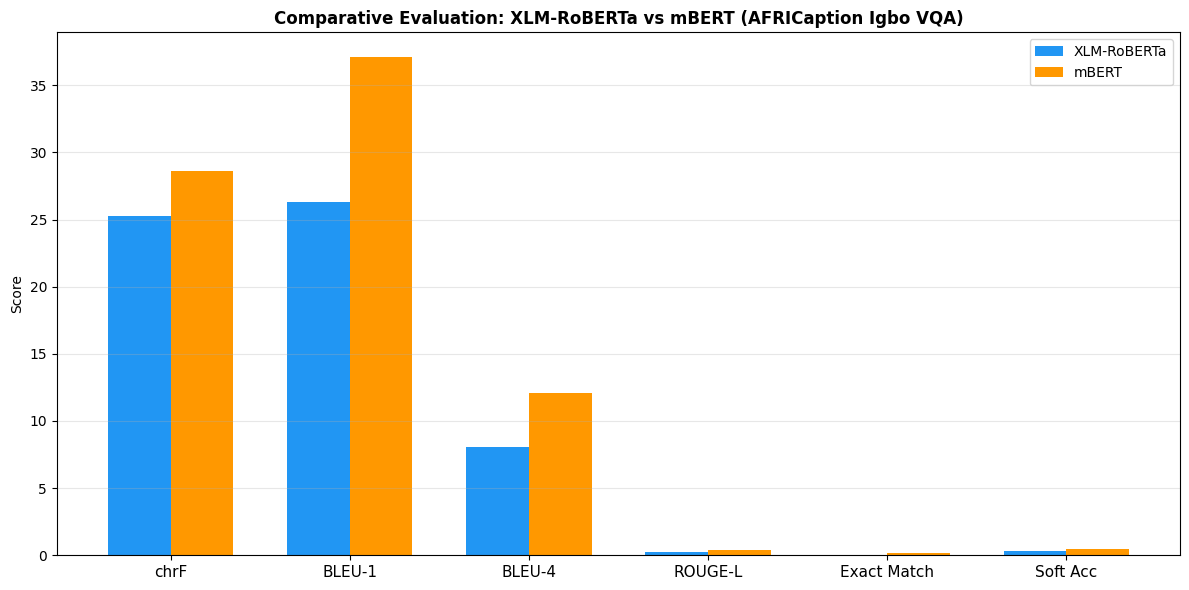

✓ Comparison plot saved: /content/igbo_vqa/results/comparison_plot.png


In [12]:
import matplotlib.pyplot as plt
import numpy as np

print("=" * 75)
print("IGBO VQA SYSTEM — ENCODER COMPARISON (Chapter 4, Table 4.1)")
print("Development of a Vision Question Answering System for Igbo Language")
print("Igboji, Ebuka Andrew (2024516019FN)")
print("=" * 75)
print(f"{'Metric':<30} {'XLM-RoBERTa':>18} {'mBERT':>15}")
print("-" * 68)

metrics_display = [
    ("chrF (Popović, 2015)", "chrf"),
    ("BLEU-1 (Unigram Overlap)", "bleu1"),
    ("BLEU-2 (Bigram Overlap)", "bleu2"),
    ("BLEU-3 (Trigram Overlap)", "bleu3"),
    ("BLEU-4 (4-gram Overlap)", "bleu4"),
    ("ROUGE-L (Unicode-safe LCS)", "rouge_l"),
    ("Exact Match Accuracy", "exact_match"),
    ("Soft Accuracy", "soft_accuracy"),
    ("Test Cross-Entropy Loss", "test_loss"),
]

for label, key in metrics_display:
    x = xlmr_metrics.get(key, 0.0)
    m = mbert_metrics.get(key, 0.0)
    win = "◀" if (x > m and key != "test_loss") else "▶" if (m > x and key != "test_loss") else " "
    print(f"{label:<30} {x:>18.4f} {m:>15.4f}  {win}")
print("=" * 75)

# Plot Comparison Bar Chart
fig, ax = plt.subplots(figsize=(12, 6))
keys_plot = ["chrf", "bleu1", "bleu4", "rouge_l", "exact_match", "soft_accuracy"]
names_plot = ["chrF", "BLEU-1", "BLEU-4", "ROUGE-L", "Exact Match", "Soft Acc"]
x = np.arange(len(keys_plot)); w = 0.35
b1 = ax.bar(x - w/2, [xlmr_metrics.get(k, 0) for k in keys_plot], w, label="XLM-RoBERTa", color="#2196F3")
b2 = ax.bar(x + w/2, [mbert_metrics.get(k, 0) for k in keys_plot], w, label="mBERT", color="#FF9800")
ax.set_xticks(x); ax.set_xticklabels(names_plot, fontsize=11)
ax.set_ylabel("Score"); ax.set_title("Comparative Evaluation: XLM-RoBERTa vs mBERT (AFRICaption Igbo VQA)", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plot_file = "/content/igbo_vqa/results/comparison_plot.png"
plt.savefig(plot_file, dpi=150)
plt.show()
print(f"✓ Comparison plot saved: {plot_file}")

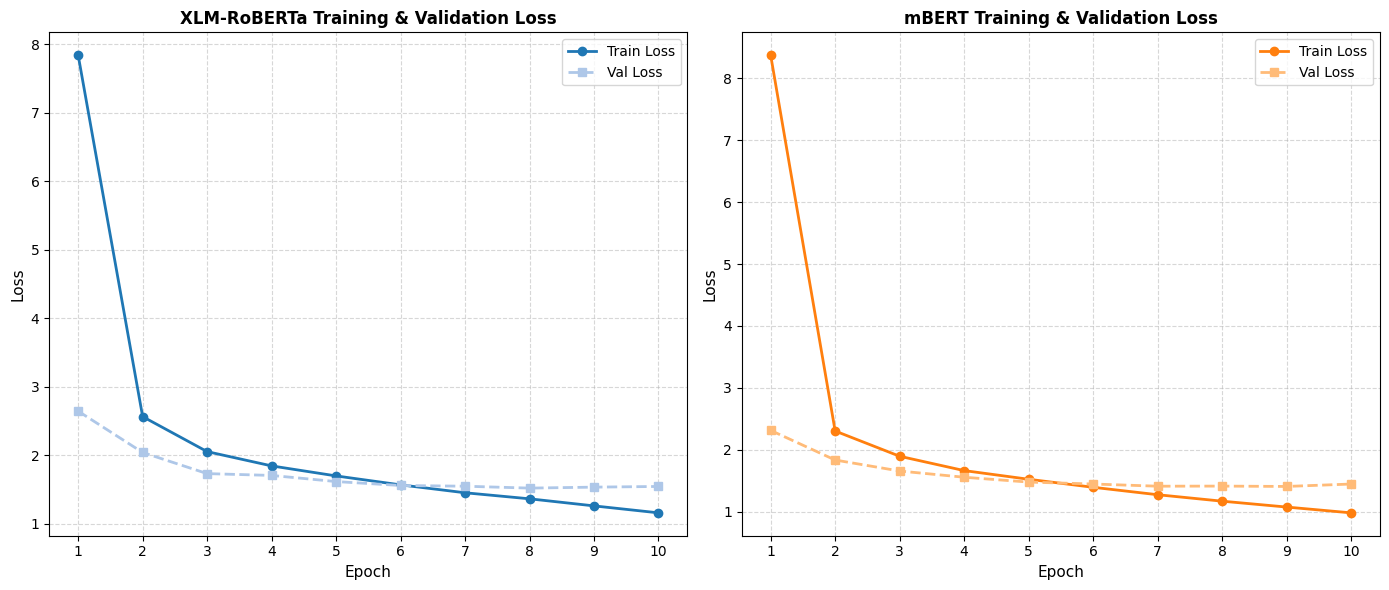

✓ Loss curves plot saved and backed up to: /content/drive/MyDrive/IgboVQA/loss_curves.png


In [13]:
import matplotlib.pyplot as plt

# Extract epochs and losses
epochs = [h['epoch'] for h in xlmr_history]
xlmr_train_loss = [h['train_loss'] for h in xlmr_history]
xlmr_val_loss = [h['val_loss'] for h in xlmr_history]

mbert_train_loss = [h['train_loss'] for h in mbert_history]
mbert_val_loss = [h['val_loss'] for h in mbert_history]

# Set up the figure
plt.figure(figsize=(14, 6))

# XLM-RoBERTa loss curve
plt.subplot(1, 2, 1)
plt.plot(epochs, xlmr_train_loss, 'o-', label='Train Loss', color='#1F77B4', linewidth=2)
plt.plot(epochs, xlmr_val_loss, 's--', label='Val Loss', color='#aec7e8', linewidth=2)
plt.title('XLM-RoBERTa Training & Validation Loss', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# mBERT loss curve
plt.subplot(1, 2, 2)
plt.plot(epochs, mbert_train_loss, 'o-', label='Train Loss', color='#FF7F0E', linewidth=2)
plt.plot(epochs, mbert_val_loss, 's--', label='Val Loss', color='#ffbb78', linewidth=2)
plt.title('mBERT Training & Validation Loss', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()

# Save the training curves image
loss_plot_file = "/content/igbo_vqa/results/loss_curves.png"
plt.savefig(loss_plot_file, dpi=150)
import shutil
shutil.copy(loss_plot_file, DRIVE_DIR)

plt.show()
print(f"✓ Loss curves plot saved and backed up to: {DRIVE_DIR}/loss_curves.png")

## 💾 Step 6: Backup Checkpoints & Metrics to Google Drive

In [14]:
import shutil
import json

shutil.copytree("/content/igbo_vqa/checkpoints", f"{DRIVE_DIR}/checkpoints", dirs_exist_ok=True)
shutil.copytree("/content/igbo_vqa/results",     f"{DRIVE_DIR}/results",     dirs_exist_ok=True)
shutil.copy("/content/igbo_vqa/results/comparison_plot.png", DRIVE_DIR)

comparison = {
    "xlmr": xlmr_metrics,
    "mbert": mbert_metrics,
    "dataset": "AfriMM/AFRICaption (Igbo)",
    "visual_encoder": "openai/clip-vit-base-patch32",
    "decoder": "google/mt5-small"
}
with open(f"{DRIVE_DIR}/comparison_results.json", "w") as f:
    json.dump(comparison, f, indent=2)
print(f"✅ All model checkpoints and results backed up to: {DRIVE_DIR}")

✅ All model checkpoints and results backed up to: /content/drive/MyDrive/IgboVQA


## 🔬 Step 7: Final Evaluation (full test set, patched decoding)
Supersedes the earlier "Thesis Correction 1-3" cells, which used only 80-160 test samples and a decoding patch applied after the headline results were produced.
Outputs: final Table 4.1, 95% bootstrap confidence intervals, real / blank / shuffled image controls, and a breakdown by question type with and without the trivial yes/no template.

In [15]:
# 7.1 Imports for the evaluation section
import os, sys, json, random
sys.path.insert(0, "/content/igbo_vqa")
import torch, numpy as np, pandas as pd
import config, data.dataset
from models.igbo_vqa_model import IgboVQAModel
from evaluation.metrics import compute_all_metrics, normalise_igbo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DECODE = dict(num_beams=4, max_new_tokens=32, repetition_penalty=1.25, no_repeat_ngram_size=3)
print("device:", device, "| decoding:", DECODE)

device: cuda | decoding: {'num_beams': 4, 'max_new_tokens': 32, 'repetition_penalty': 1.25, 'no_repeat_ngram_size': 3}


In [16]:
# 3. Load the test set once (same seed and split as training) and both trained models
from transformers import CLIPProcessor, AutoTokenizer
ip = CLIPProcessor.from_pretrained(config.VISUAL_ENCODER_NAME)

def load_model(key):
    name = config.ENCODER_VARIANTS[key]
    m = IgboVQAModel(text_encoder_name=name).to(device)
    ck = torch.load(config.get_checkpoint_path(key), map_location=device, weights_only=False)
    m.load_state_dict(ck["model_state_dict"]); m.eval()
    return m, AutoTokenizer.from_pretrained(name)

def test_loader(tokenizer, decoder_tokenizer):
    _, _, te = data.dataset.get_dataloaders(ip, tokenizer, batch_size=16, decoder_tokenizer=decoder_tokenizer)
    return te
print("ready")

ready


In [17]:
# 4. Run all conditions on the FULL test set for both encoders
from evaluation.metrics import normalise_igbo
import pandas as pd
RESULTS = {}      # key -> condition -> dict(preds, refs, qtypes)
template_map = {t["template"]: t["type"] for t in config.IGBO_QUESTION_TEMPLATES}

def run_condition(model, te, mode):
    preds, refs, qtypes, qtexts = [], [], [], []
    g = torch.Generator(device="cpu").manual_seed(42)
    with torch.no_grad():
        for b in te:
            pv = b["pixel_values"].to(device); qi = b["question_ids"].to(device); qm = b["question_mask"].to(device)
            if mode == "blank":      pv = torch.zeros_like(pv)                 # zeroed (mean-colour) image
            elif mode == "shuffled": pv = pv.roll(shifts=1, dims=0)            # image of a different sample
            preds.extend(model.generate_answer(pv, qi, qm))
            refs.extend(b["answer_text"]); qtexts.extend(b["question_text"])
            qtypes.extend(template_map.get(q, "general") for q in b["question_text"])
    return dict(preds=preds, refs=refs, qtypes=qtypes, qtexts=qtexts)

for key in ["xlmr", "mbert"]:
    model, tk = load_model(key)
    te = test_loader(tk, model.mt5_tokenizer)
    RESULTS[key] = {}
    for mode in ["real", "blank", "shuffled"]:
        RESULTS[key][mode] = run_condition(model, te, mode)
        print(key, mode, "n =", len(RESULTS[key][mode]["preds"]))
    pd.DataFrame(RESULTS[key]["real"]).to_csv(f"{DRIVE_DIR}/predictions_{key}_real.csv", index=False)
    del model; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_n

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


... (4 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


✓ Matched real Flickr8k images: 6000/6000
mbert real n = 900
mbert blank n = 900
mbert shuffled n = 900


In [18]:
# 5. Table 4.1: final metrics (patched decoding, full test set, real images)
from evaluation.metrics import compute_all_metrics
FINAL = {k: compute_all_metrics(RESULTS[k]["real"]["preds"], RESULTS[k]["real"]["refs"]) for k in RESULTS}
rows = [("chrF","chrf"),("BLEU-1","bleu1"),("BLEU-2","bleu2"),("BLEU-3","bleu3"),("BLEU-4","bleu4"),
        ("ROUGE-L (0-1)","rouge_l"),("Exact Match (0-1)","exact_match"),("Soft accuracy (0-1)","soft_accuracy")]
print(f"{'Metric':<22}{'XLM-RoBERTa':>14}{'mBERT':>12}")
for lab,k in rows: print(f"{lab:<22}{FINAL['xlmr'][k]:>14.4f}{FINAL['mbert'][k]:>12.4f}")
print("n test samples:", len(RESULTS['xlmr']['real']['preds']))

Metric                   XLM-RoBERTa       mBERT
chrF                         25.2356     28.5984
BLEU-1                       26.3190     37.0846
BLEU-2                       16.7229     24.0829
BLEU-3                       11.4246     16.9280
BLEU-4                        8.0285     12.0825
ROUGE-L (0-1)                 0.2442      0.4254
Exact Match (0-1)             0.0067      0.1578
Soft accuracy (0-1)           0.2819      0.4360
n test samples: 900


In [19]:
# 6. 95% bootstrap CIs and a paired bootstrap test (XLM-R minus mBERT)
import sacrebleu
def norm(xs): return [normalise_igbo(x) for x in xs]
P = {k: norm(RESULTS[k]["real"]["preds"]) for k in RESULTS}
R = norm(RESULTS["xlmr"]["real"]["refs"])
assert R == norm(RESULTS["mbert"]["real"]["refs"]), "test sets differ between encoders"
bleu4 = sacrebleu.BLEU(max_ngram_order=4, smooth_method="exp")
def stats(p, r):
    return np.array([sacrebleu.corpus_chrf(p,[r],beta=2.0).score, bleu4.corpus_score(p,[r]).score,
                     np.mean([a==b for a,b in zip(p,r)])])
rng = np.random.default_rng(42); N = len(R); B = 1000
bs = {k: [] for k in P}; diff = []
for _ in range(B):
    idx = rng.integers(0, N, N); r = [R[i] for i in idx]
    s = {k: stats([P[k][i] for i in idx], r) for k in P}
    for k in P: bs[k].append(s[k])
    diff.append(s["xlmr"] - s["mbert"])
bs = {k: np.array(v) for k,v in bs.items()}; diff = np.array(diff)
names = ["chrF","BLEU-4","Exact Match"]
CI = {}
for k in P:
    lo, hi = np.percentile(bs[k], [2.5, 97.5], axis=0)
    CI[k] = {n:(float(a),float(b)) for n,a,b in zip(names, lo, hi)}
    print(k, {n:f"{a:.2f}-{b:.2f}" if n!="Exact Match" else f"{a:.3f}-{b:.3f}" for n,(a,b) in CI[k].items()})
lo, hi = np.percentile(diff, [2.5, 97.5], axis=0)
DIFF = {}
for i,n in enumerate(names):
    p_two = 2*min((diff[:,i] <= 0).mean(), (diff[:,i] >= 0).mean())
    DIFF[n] = dict(mean=float(diff[:,i].mean()), ci=(float(lo[i]),float(hi[i])), p=float(p_two))
    print(f"XLM-R minus mBERT, {n}: {diff[:,i].mean():+.3f}  95% CI [{lo[i]:+.3f}, {hi[i]:+.3f}]  p~{p_two:.3f}")
print("If a CI contains 0, the encoders are NOT significantly different on that metric.")

xlmr {'chrF': '23.88-26.62', 'BLEU-4': '6.61-9.43', 'Exact Match': '0.002-0.012'}
mbert {'chrF': '27.03-30.11', 'BLEU-4': '10.24-13.93', 'Exact Match': '0.137-0.183'}
XLM-R minus mBERT, chrF: -3.357  95% CI [-4.734, -2.002]  p~0.000
XLM-R minus mBERT, BLEU-4: -4.085  95% CI [-5.684, -2.485]  p~0.000
XLM-R minus mBERT, Exact Match: -0.152  95% CI [-0.177, -0.129]  p~0.000
If a CI contains 0, the encoders are NOT significantly different on that metric.


In [20]:
# 7. Grounding controls: real vs blank vs shuffled image (full test set, both encoders)
CTRL = {}
print(f"{'Encoder':<8}{'Condition':<10}{'chrF':>8}{'BLEU-4':>9}{'EM':>8}")
for k in RESULTS:
    CTRL[k] = {}
    for mode in ["real","blank","shuffled"]:
        m = compute_all_metrics(RESULTS[k][mode]["preds"], RESULTS[k][mode]["refs"]); CTRL[k][mode] = m
        print(f"{k:<8}{mode:<10}{m['chrf']:>8.2f}{m['bleu4']:>9.2f}{m['exact_match']:>8.4f}")
    d = CTRL[k]["real"]["chrf"] - CTRL[k]["blank"]["chrf"]
    print(f"  -> image contribution ({k}): +{d:.2f} chrF over the blank-image control\n")

Encoder Condition     chrF   BLEU-4      EM
xlmr    real         25.24     8.03  0.0067
xlmr    blank        13.82     1.91  0.0000
xlmr    shuffled     13.90     2.05  0.0000
  -> image contribution (xlmr): +11.42 chrF over the blank-image control

mbert   real         28.60    12.08  0.1578
mbert   blank        16.52     3.69  0.1311
mbert   shuffled     15.13     2.31  0.1311
  -> image contribution (mbert): +12.08 chrF over the blank-image control



In [21]:
# 8. Breakdown by question type, with and without the yes/no template (full test set)
from collections import defaultdict
BREAK = {}
for k in RESULTS:
    d = RESULTS[k]["real"]; by = defaultdict(lambda: ([],[]))
    for p,r,t in zip(d["preds"], d["refs"], d["qtypes"]): by[t][0].append(p); by[t][1].append(r)
    BREAK[k] = {t: dict(n=len(v[0]), **compute_all_metrics(v[0], v[1])) for t,v in by.items()}
    keep = [(p,r) for p,r,t in zip(d["preds"], d["refs"], d["qtypes"]) if t != "yes_no"]
    BREAK[k]["ALL_EXCL_YES_NO"] = dict(n=len(keep), **compute_all_metrics([a for a,_ in keep],[b for _,b in keep]))
    BREAK[k]["ALL"] = dict(n=len(d["preds"]), **FINAL[k])
    print(f"\n=== {k.upper()} ===")
    print(f"{'Type':<18}{'n':>5}{'chrF':>9}{'BLEU-4':>9}{'EM':>8}")
    for t in sorted(BREAK[k]):
        m = BREAK[k][t]; print(f"{t:<18}{m['n']:>5}{m['chrf']:>9.2f}{m['bleu4']:>9.2f}{m['exact_match']:>8.4f}")
print("\nNote: yes_no answers are always 'Ee' by construction, so that row is trivial and must not be read as VQA skill.")


=== XLMR ===
Type                  n     chrF   BLEU-4      EM
ALL                 900    25.24     8.03  0.0067
ALL_EXCL_YES_NO     791    25.61     9.14  0.0076
action              192    21.62     8.16  0.0000
color               101    26.79    11.11  0.0000
general             295    26.00     9.28  0.0000
object              203    29.00     1.55  0.0296
yes_no              109     9.39     0.00  0.0000

=== MBERT ===
Type                  n     chrF   BLEU-4      EM
ALL                 900    28.60    12.08  0.1578
ALL_EXCL_YES_NO     791    28.42    11.94  0.0417
action              192    22.52    10.25  0.0052
color               101    32.14    15.81  0.0099
general             295    29.72    11.36  0.0068
object              203    28.00     0.00  0.1429
yes_no              109   100.00     0.00  1.0000

Note: yes_no answers are always 'Ee' by construction, so that row is trivial and must not be read as VQA skill.


In [22]:
# 9. Save everything: JSON, LaTeX table for Chapter 4, and a few real predictions for the appendix
out = dict(decoding=DECODE, n_test=len(R), final=FINAL, controls=CTRL, breakdown=BREAK, bootstrap_ci=CI, paired_difference=DIFF)
with open(f"{DRIVE_DIR}/final_results.json","w",encoding="utf-8") as f: json.dump(out,f,indent=2,ensure_ascii=False)
tex = r"""\begin{table}[htbp]
\centering
\caption{Quantitative Evaluation of the Igbo VQA System on the Test Set ($n=%d$)}
\label{tab:results}
\begin{tabular}{|l|c|c|}
\hline
\textbf{Metric} & \textbf{XLM-RoBERTa} & \textbf{mBERT} \\ \hline
""" % len(R)
for lab,k in rows: tex += f"{lab} & {FINAL['xlmr'][k]:.4f} & {FINAL['mbert'][k]:.4f} \\\\ \\hline\n"
tex += "\\end{tabular}\n\\end{table}\n"
open(f"{DRIVE_DIR}/table_4_1.tex","w",encoding="utf-8").write(tex)
print(tex); print("saved to", DRIVE_DIR)

\begin{table}[htbp]
\centering
\caption{Quantitative Evaluation of the Igbo VQA System on the Test Set ($n=900$)}
\label{tab:results}
\begin{tabular}{|l|c|c|}
\hline
\textbf{Metric} & \textbf{XLM-RoBERTa} & \textbf{mBERT} \\ \hline
chrF & 25.2356 & 28.5984 \\ \hline
BLEU-1 & 26.3190 & 37.0846 \\ \hline
BLEU-2 & 16.7229 & 24.0829 \\ \hline
BLEU-3 & 11.4246 & 16.9280 \\ \hline
BLEU-4 & 8.0285 & 12.0825 \\ \hline
ROUGE-L (0-1) & 0.2442 & 0.4254 \\ \hline
Exact Match (0-1) & 0.0067 & 0.1578 \\ \hline
Soft accuracy (0-1) & 0.2819 & 0.4360 \\ \hline
\end{tabular}
\end{table}

saved to /content/drive/MyDrive/IgboVQA


## Optional ablation: does transfer learning help? (decoder trained from random weights)
Training takes about as long as the original run per encoder. **Back up your checkpoints first** (Step 6 of the training notebook). This cell trains XLM-R with a randomly initialised mT5 decoder and writes to a *separate* checkpoint folder, so the trained model is not overwritten.

In [23]:
RUN_SCRATCH_ABLATION = False   # set True to train XLM-R with a randomly initialised mT5 decoder (takes as long as one full training run)
if RUN_SCRATCH_ABLATION:
    # 10. (Optional) From-scratch decoder ablation, XLM-R only
    import training.train_model as T
    from transformers import MT5ForConditionalGeneration, MT5Config
    _orig_init = IgboVQAModel.__init__
    def scratch_init(self, *a, **k):
        _orig_init(self, *a, **k)
        self.decoder = MT5ForConditionalGeneration(MT5Config.from_pretrained(config.DECODER_NAME))   # random weights
    IgboVQAModel.__init__ = scratch_init
    old = (config.XLMR_BEST_CHECKPOINT, config.XLMR_RESULTS_DIR)
    config.XLMR_BEST_CHECKPOINT = "/content/igbo_vqa/checkpoints/xlmr_scratch/best_model.pt"
    config.XLMR_RESULTS_DIR = "/content/igbo_vqa/results/xlmr_scratch"
    os.makedirs("/content/igbo_vqa/checkpoints/xlmr_scratch", exist_ok=True); os.makedirs(config.XLMR_RESULTS_DIR, exist_ok=True)
    scratch_metrics, _ = T.train_one_encoder(encoder_key="xlmr")
    IgboVQAModel.__init__ = _orig_init; config.XLMR_BEST_CHECKPOINT, config.XLMR_RESULTS_DIR = old
    print("Pretrained mT5 decoder :", {k: FINAL['xlmr'][k] for k in ['chrf','bleu4','exact_match']})
    print("Random-init decoder    :", {k: scratch_metrics[k] for k in ['chrf','bleu4','exact_match']})
    json.dump(scratch_metrics, open(f"{DRIVE_DIR}/scratch_decoder_metrics.json","w"), indent=2)

## 📝 Step 8: Draft Text for Chapter 4 (claims follow the statistics)

In [24]:
# 8. Draft wording for Chapter 4, generated from the numbers above (claims depend on the statistics)
x, m = FINAL["xlmr"], FINAL["mbert"]
def sig(name): return not (DIFF[name]["ci"][0] <= 0 <= DIFF[name]["ci"][1])
if sig("chrF"):
    enc = ("XLM-RoBERTa obtained a higher chrF than mBERT (difference %+.2f, 95%% CI [%+.2f, %+.2f])." % (DIFF["chrF"]["mean"], *DIFF["chrF"]["ci"])) if DIFF["chrF"]["mean"] > 0 else ("mBERT obtained a higher chrF than XLM-RoBERTa (difference %+.2f, 95%% CI [%+.2f, %+.2f])." % (-DIFF["chrF"]["mean"], -DIFF["chrF"]["ci"][1], -DIFF["chrF"]["ci"][0]))
else:
    enc = ("The difference between the two encoders was not statistically significant (chrF difference %+.2f, 95%% CI [%+.2f, %+.2f]), so neither encoder can be declared superior on this test set." % (DIFF["chrF"]["mean"], *DIFF["chrF"]["ci"]))
dr = CTRL["xlmr"]["real"]["chrf"] - CTRL["xlmr"]["blank"]["chrf"]; ds = CTRL["xlmr"]["real"]["chrf"] - CTRL["xlmr"]["shuffled"]["chrf"]
ground = ("Replacing the image with a blank image reduced chrF from %.2f to %.2f, and replacing it with the image of a different sample reduced it to %.2f. "
          "The model therefore uses visual information, although a substantial part of the score is explained by language priors in the questions and answers." % (CTRL["xlmr"]["real"]["chrf"], CTRL["xlmr"]["blank"]["chrf"], CTRL["xlmr"]["shuffled"]["chrf"])) if dr > 2 and ds > 2 else \
         (("Replacing the image with a blank or shuffled image changed chrF by only %.2f and %.2f points, so the model relies mainly on language priors and its use of the image is weak." % (dr, ds)) if (dr <= 2 and ds <= 2) else ("The image controls gave mixed evidence: a blank image changed chrF by %.2f points and a shuffled image by %.2f points, so the use of visual information is not clearly established." % (dr, ds)))
ex = BREAK["xlmr"]["ALL_EXCL_YES_NO"]
text = f"""CHAPTER 4 DRAFT TEXT (generated; check every number against the tables above)

4.3 Experimental Results
Table 4.1 reports the results on the held-out test set of {len(R)} samples, decoded with beam search (4 beams), a repetition penalty of 1.25 and a restriction on repeated 3-grams.
XLM-RoBERTa: chrF {x['chrf']:.2f}, BLEU-4 {x['bleu4']:.2f}, ROUGE-L {x['rouge_l']:.4f}, Exact Match {x['exact_match']:.4f}.
mBERT: chrF {m['chrf']:.2f}, BLEU-4 {m['bleu4']:.2f}, ROUGE-L {m['rouge_l']:.4f}, Exact Match {m['exact_match']:.4f}.
chrF and BLEU are on a 0-100 scale; ROUGE-L and Exact Match are on a 0-1 scale.
{enc}

4.4 Grounding Analysis
{ground}

4.5 Performance by Question Type
Yes/no questions always have the answer "Ee" by construction, so they are reported separately and excluded from the headline analysis below.
Excluding yes/no questions (n = {ex['n']}), XLM-RoBERTa obtained chrF {ex['chrf']:.2f} and Exact Match {ex['exact_match']:.4f}.
Question types are labels attached to the question templates; the answers are short spans of the Igbo caption, so a type label does not guarantee that the answer is of that type.

4.6 Limitations
The captions are machine translated and contain truncated or partly English references; the dataset is limited to {config.MAX_SAMPLES} samples; each model was trained once with seed {config.SEED}; AFRICaption's scores (Oduwole et al., 2026) are for captioning and are not comparable with these question-answering scores.
"""
print(text)
with open(f"{DRIVE_DIR}/chapter4_draft_text.txt", "w", encoding="utf-8") as f: f.write(text)
print("saved to", DRIVE_DIR)

CHAPTER 4 DRAFT TEXT (generated; check every number against the tables above)

4.3 Experimental Results
Table 4.1 reports the results on the held-out test set of 900 samples, decoded with beam search (4 beams), a repetition penalty of 1.25 and a restriction on repeated 3-grams.
XLM-RoBERTa: chrF 25.24, BLEU-4 8.03, ROUGE-L 0.2442, Exact Match 0.0067.
mBERT: chrF 28.60, BLEU-4 12.08, ROUGE-L 0.4254, Exact Match 0.1578.
chrF and BLEU are on a 0-100 scale; ROUGE-L and Exact Match are on a 0-1 scale.
mBERT obtained a higher chrF than XLM-RoBERTa (difference +3.36, 95% CI [+2.00, +4.73]).

4.4 Grounding Analysis
Replacing the image with a blank image reduced chrF from 25.24 to 13.82, and replacing it with the image of a different sample reduced it to 13.90. The model therefore uses visual information, although a substantial part of the score is explained by language priors in the questions and answers.

4.5 Performance by Question Type
Yes/no questions always have the answer "Ee" by constru

### 🖼️ Dataset Domain Information & Sample Visualization
Below, we analyze the domain background of our VQA dataset and visualize actual image-question-answer triplets from the AFRICaption (Igbo) corpus.


📊 DATASET DOMAIN & SPECIFICATION SHEET
- **Source Dataset**: AfriMM / AFRICaption (Igbo Cohort)
- **Visual Domain**: Everyday activities, human actions, objects, animals,
                     and scenes sourced from the Flickr8k dataset.
- **Language Domain**: Igbo (Niger-Congo family, primarily spoken in Nigeria).
- **Characteristics of Igbo Morphology**:
  - Highly agglutinative structure (prefixes/suffixes alter root meanings).
  - Tone-marking dependency and vowel harmony (e.g., matching heavy/light vowels: i/ị, o/ọ, u/ụ).
- **VQA Task Adaptation**:
  - Instead of standard image captioning, the templates convert captions into
    structured question-answer tasks.
  - Question Types: Object Identification, Action Descriptions, Color attributes, and Yes/No Queries.



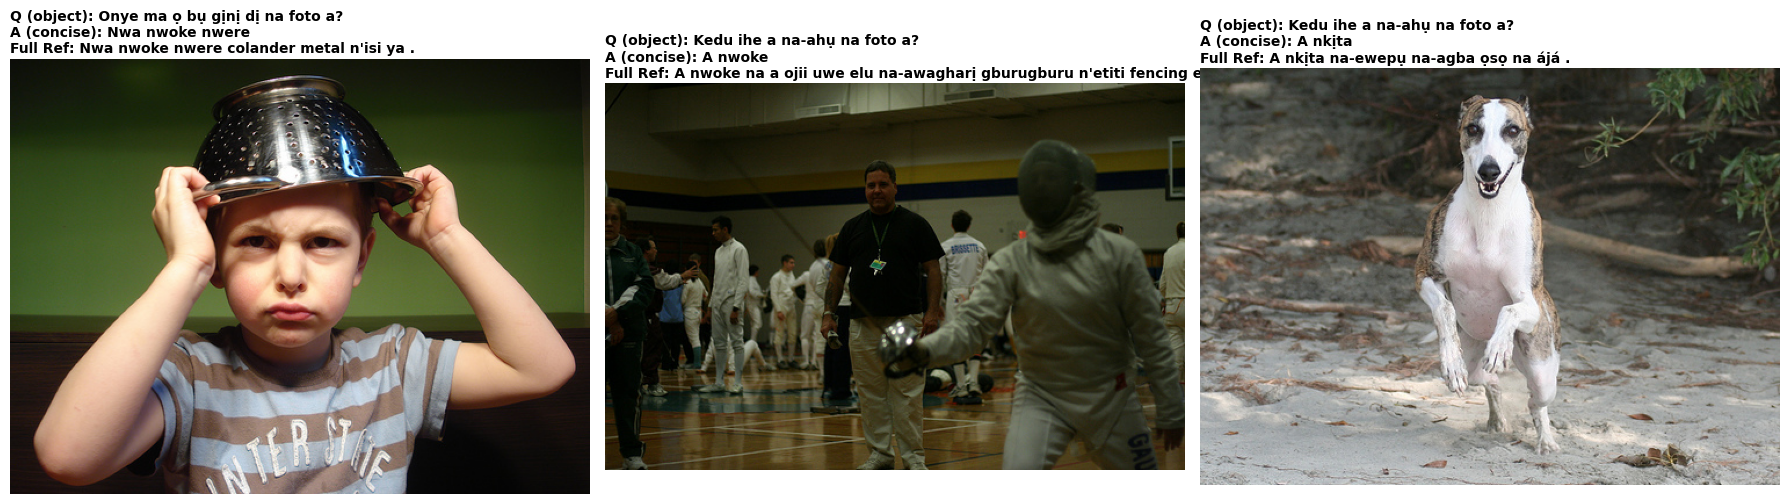

In [25]:
import os
import random
import json
import matplotlib.pyplot as plt
from PIL import Image

# --- 1. Dataset Domain & Corpus Information ---
domain_info = """
====================================================================
📊 DATASET DOMAIN & SPECIFICATION SHEET
====================================================================
- **Source Dataset**: AfriMM / AFRICaption (Igbo Cohort)
- **Visual Domain**: Everyday activities, human actions, objects, animals,
                     and scenes sourced from the Flickr8k dataset.
- **Language Domain**: Igbo (Niger-Congo family, primarily spoken in Nigeria).
- **Characteristics of Igbo Morphology**:
  - Highly agglutinative structure (prefixes/suffixes alter root meanings).
  - Tone-marking dependency and vowel harmony (e.g., matching heavy/light vowels: i/ị, o/ọ, u/ụ).
- **VQA Task Adaptation**:
  - Instead of standard image captioning, the templates convert captions into
    structured question-answer tasks.
  - Question Types: Object Identification, Action Descriptions, Color attributes, and Yes/No Queries.
====================================================================
"""
print(domain_info)

# --- 2. Load Sample VQA Pairs & Visualize ---
with open("/content/igbo_vqa/data/cache/africaption_6000.json", "r", encoding="utf-8") as f:
    raw_records = json.load(f)

sys.path.insert(0, "/content/igbo_vqa")
import config
from data.dataset import create_vqa_pairs

# Construct VQA pairs
vqa_pairs = create_vqa_pairs(raw_records)
random.seed(42)
sample_pairs = random.sample(vqa_pairs, min(3, len(vqa_pairs)))

# Plot images side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for idx, pair in enumerate(sample_pairs):
    img_path = os.path.join(config.IMAGES_DIR, os.path.basename(pair["image_id"]))
    ax = axes[idx]

    if os.path.exists(img_path):
        img = Image.open(img_path)
        ax.imshow(img)
    else:
        # Fallback colored placeholder
        ax.fill_between([0, 224], [0, 224], color='gray')
        ax.text(50, 112, "[Image Missing]", color='white', fontsize=12, fontweight='bold')

    ax.axis('off')
    title_text = (
        f"Q ({pair['question_type']}): {pair['question_igbo']}\n"
        f"A (concise): {pair['answer_igbo']}\n"
        f"Full Ref: {pair['full_caption']}"
    )
    ax.set_title(title_text, fontsize=10, loc='left', wrap=True, fontweight='semibold')

plt.tight_layout()
plt.show()